## Imports

In [16]:
%load_ext autoreload
%autoreload 2

# Standard Library
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

# Third Party
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt
from av2.datasets.motion_forecasting import scenario_serialization
from av2.datasets.motion_forecasting.eval import metrics
import tqdm
import torch
from tracs.av2.metrics import compute_weighted_metrics

# TraCS
from tracs.fusion import FusionNet

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load data

In [17]:
# Run also for "QCNet" and "Polaris" and run `python create_paper_figures.py` afterwards from project root directory
backbone = "DeMo"
program_name = "complete2"

In [18]:
data_root = Path("../data")
val_ground_truth_path = data_root / "av2" / "val_ground_truth.parquet"
test_ground_truth_path = data_root / "av2" / "av2_mf_focal_test_annotations.parquet"
test_prediction_path = data_root / "av2_backbone_outputs" / backbone / "submission_test.parquet"
train_data_path = data_root / "results" / program_name / "val" / backbone / "scored_predictions.parquet"
test_data_path = data_root / "tracs_predictions" / program_name / backbone / "test.parquet"
train_embedding_path = data_root / "av2_backbone_outputs" / backbone / "val_embeddings.parquet"
test_embedding_path = data_root / "av2_backbone_outputs" / backbone / "test_embeddings.parquet"
features_pt_path = data_root / "results" / program_name / "val" / backbone / f"features.pt"
optimal_weights_pt_path = data_root / "results" / program_name / "val" / backbone / f"optimal_weights.pt"
scores_pt_path = data_root / "results" / program_name / "val" / backbone / f"scores.pt"

## Data preparation

In [19]:
def get_val_gt_trajectory(scenario_id: str) -> pd.DataFrame:
    scenario_path = data_root / "av2" / "val" / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    future_states = [s for s in focal_track.object_states if not s.observed]
    gt = np.array([[s.position[0], s.position[1]] for s in future_states])
    return pd.DataFrame({
        "scenario_id": [scenario_id],
        "gt_trajectory_x": [gt[:, 0].tolist()],
        "gt_trajectory_y": [gt[:, 1].tolist()],
    })

In [20]:
def load_scenario_extras(scenario_id: str, split: str = "val"):
    scenario_path = data_root / "av2" / split / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    past_states = sorted([s for s in focal_track.object_states if s.observed], key=lambda s: s.timestep)
    past_xy = np.array([[s.position[0], s.position[1]] for s in past_states], dtype=np.float64)  # (50, 2)
    n_agents = sum(1 for t in scenario.tracks if any(s.observed for s in t.object_states))
    return past_xy, n_agents

In [21]:
src = data_root / "tracs_predictions" / program_name / backbone / "val.parquet"
train_data = pd.read_parquet(src).drop(columns=[
    "covariance", "is_moving", "min_dist_to_focal",
    "included_in_features", "tracs_backbone_independent_op",
    "tracs_backbone_linear_op", "tracs_pointwise_scores",
])
train_data_path.parent.mkdir(parents=True, exist_ok=True)
train_data.to_parquet(train_data_path)

In [22]:
if not val_ground_truth_path.exists():
    scenario_ids = [p.name for p in (data_root / "av2" / "val").iterdir() if p.is_dir()]
    with ThreadPoolExecutor(8) as pool:
        rows = list(tqdm.tqdm(pool.map(get_val_gt_trajectory, scenario_ids), total=len(scenario_ids)))
    pd.concat(rows, ignore_index=True).to_parquet(val_ground_truth_path)

val_gt = pd.read_parquet(val_ground_truth_path).set_index("scenario_id")

## Training

In [23]:
train_data = pd.read_parquet(train_data_path)

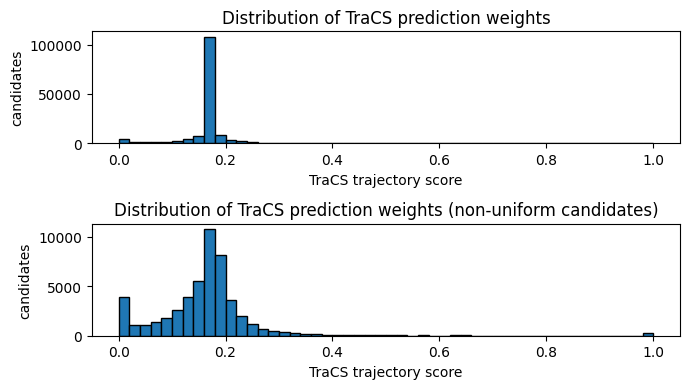

Overall: mean=0.1667  std=0.0651  min=0.0000  p25=0.1666  p50=0.1667  p75=0.1677  max=1.0000
Non uniform: mean=0.1667  std=0.1120  min=0.0000  p25=0.1255  p50=0.1715  p75=0.1926  max=1.0000


In [24]:
tracs_scores = train_data["tracs_trajectory_score"].values.reshape(-1, 6)
tracs_scores_nonuniform = tracs_scores[tracs_scores.std(axis=1) > 0.01, :].flatten()

fig, ax = plt.subplots(2, 1, figsize=(7, 4))
ax[0].hist(tracs_scores.flatten(), bins=50, edgecolor="black")
ax[0].set_xlabel("TraCS trajectory score")
ax[0].set_ylabel("candidates")
ax[0].set_title("Distribution of TraCS prediction weights")
ax[1].hist(tracs_scores_nonuniform, bins=50, edgecolor="black")
ax[1].set_xlabel("TraCS trajectory score")
ax[1].set_ylabel("candidates")
ax[1].set_title("Distribution of TraCS prediction weights (non-uniform candidates)")
plt.tight_layout()
plt.show()

v = tracs_scores.flatten()
print(f"Overall: mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

v = tracs_scores_nonuniform
print(f"Non uniform: mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

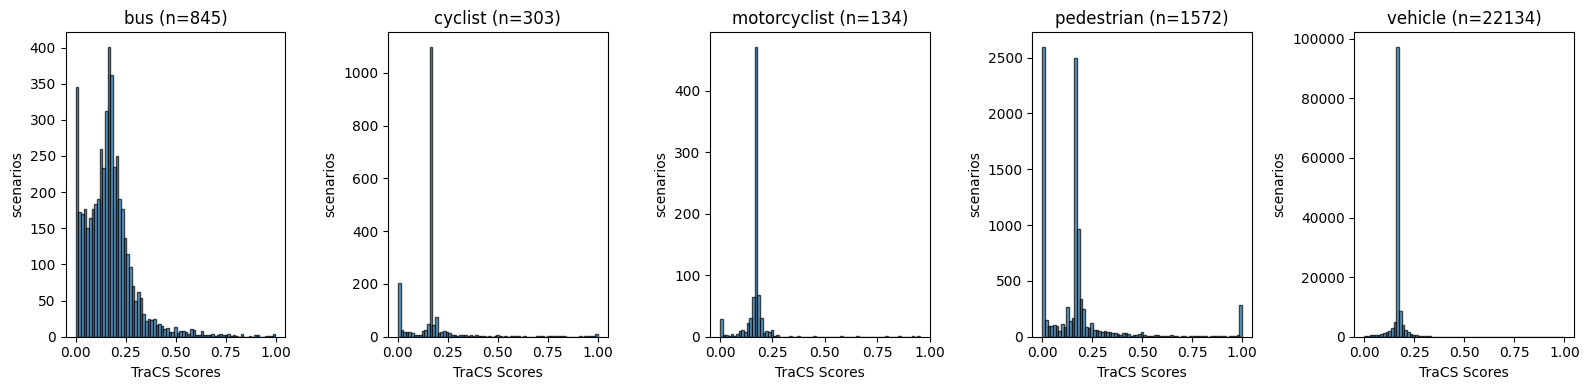

In [38]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(16, 4))
agent_types = train_data["agent_type"].values[::6]
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(1, 5, i+1)
    mask = agent_types == vtype
    agent_tracs_scores = tracs_scores[mask, :]
    plt.hist(agent_tracs_scores.flatten(), bins=75, edgecolor="black", alpha=0.7)
    plt.xlabel("TraCS Scores")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
plt.tight_layout()
plt.show()

In [ ]:
train_emb = pd.read_parquet(train_embedding_path).set_index("scenario_id")

def _process_scenario(args):
    scenario_id, scenario_data = args
    gt_row = val_gt.loc[scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"]),
        np.array(gt_row["gt_trajectory_y"])
    ], axis=1).astype(np.float64)

    log_tracs_scores = np.log(np.array(scenario_data["tracs_trajectory_score"]) + 1e-10)
    log_backbone_scores = np.log(np.array(scenario_data["backbone_trajectory_score"]) + 1e-10)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    # past_xy, n_agents = load_scenario_extras(scenario_id, split="val")
    w, original_score, optimal_score = FusionNet.optimal_weight(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track)

    emb_row = train_emb.loc[scenario_id]
    embedding = np.concatenate([emb_row["focal_embedding"], emb_row["average_embedding"]]).astype(np.float32)

    features = FusionNet.extract_features(
        predicted_tracks,
        focal_type=scenario_data["agent_type"].iloc[0],
        backbone_scores=np.array(scenario_data["backbone_trajectory_score"]),
        tracs_scores=np.array(scenario_data["tracs_trajectory_score"]),
        embedding=embedding,
    )
    return features, w, original_score, optimal_score


if not features_pt_path.exists() or not optimal_weights_pt_path.exists() or not scores_pt_path.exists():
    groups = list(train_data.groupby("scenario_id"))
    with ThreadPoolExecutor(8) as pool:
        results = list(tqdm.tqdm(pool.map(_process_scenario, groups), total=len(groups)))

    all_features, all_weights, all_original_scores, all_optimal_scores = zip(*results)
    X = torch.tensor(np.stack(all_features), dtype=torch.float32)
    Y = torch.tensor(np.array(all_weights), dtype=torch.float32)
    all_original_scores = torch.tensor(np.array(all_original_scores), dtype=torch.float32)
    all_optimal_scores = torch.tensor(np.array(all_optimal_scores), dtype=torch.float32)
    print(f"Dataset: {X.shape} features, {Y.shape} labels")

    torch.save(X, features_pt_path)
    torch.save(Y, optimal_weights_pt_path)
    torch.save((all_original_scores, all_optimal_scores), scores_pt_path)

else:
    X = torch.load(features_pt_path, weights_only=True)
    Y = torch.load(optimal_weights_pt_path, weights_only=True)
    all_original_scores, all_optimal_scores = torch.load(scores_pt_path)

    X.shape, Y.shape, len(all_original_scores), len(all_optimal_scores)

In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X, Y = X.to(device), Y.to(device)

# Deterministic 90/10 train/val split by scenario index
g = torch.Generator(device="cpu").manual_seed(0)
perm = torch.randperm(len(X), generator=g)
n_val = int(0.1 * len(X))
val_idx = perm[:n_val].to(device)
train_idx = perm[n_val:].to(device)
X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

model = FusionNet(X.shape[1]).to(device)
train_losses, val_losses = model.fit(X_train, Y_train, X_val, Y_val, n_epochs=500, batch_size=256, min_improvement=1e-5, patience=30, device=device, verbose=True)


Train: 22490  Val: 2498
Epoch   0: train=0.6027  val=0.6003  lr=1.00e-03  patience=0/30 *
Epoch   1: train=0.5902  val=0.5893  lr=1.00e-03  patience=0/30 *
Epoch   2: train=0.5857  val=0.5877  lr=1.00e-03  patience=0/30 *
Epoch   3: train=0.5803  val=0.5844  lr=1.00e-03  patience=0/30 *
Epoch   4: train=0.5765  val=0.5834  lr=1.00e-03  patience=0/30 *
Epoch   5: train=0.5758  val=0.5822  lr=1.00e-03  patience=0/30 *
Epoch   6: train=0.5733  val=0.5808  lr=1.00e-03  patience=0/30 *
Epoch   7: train=0.5713  val=0.5802  lr=1.00e-03  patience=0/30 *
Epoch   8: train=0.5683  val=0.5795  lr=1.00e-03  patience=0/30 *
Epoch  10: train=0.5651  val=0.5772  lr=1.00e-03  patience=0/30 *
Epoch  12: train=0.5621  val=0.5764  lr=1.00e-03  patience=0/30 *
Epoch  13: train=0.5603  val=0.5762  lr=1.00e-03  patience=0/30 *
Epoch  20: train=0.5509  val=0.5770  lr=1.00e-03  patience=7/30
Epoch  22: train=0.5486  val=0.5761  lr=1.00e-03  patience=0/30 *
Epoch  24: train=0.5458  val=0.5757  lr=1.00e-03  pati

In [28]:
# --- Select fusion threshold on the held-out val split (not test) ---
# Arrays are rebuilt in groupby order so they align row-for-row with X.
model.eval()
with torch.no_grad():
    w_all = model(X).cpu().numpy()          # predicted weight per training scenario, aligned with X

ade_rows, bb_rows, tr_rows, agent_rows = [], [], [], []
for scenario_id, sd in tqdm.tqdm(train_data.groupby("scenario_id")):
    gt_row = val_gt.loc[scenario_id]
    gt_track = np.stack([np.array(gt_row["gt_trajectory_x"]),
                         np.array(gt_row["gt_trajectory_y"])], axis=1).astype(np.float64)
    predicted_tracks = np.moveaxis(
        np.array([[*sd["x_traj"]], [*sd["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1]).astype(np.float64)
    bb = np.array(sd["backbone_trajectory_score"], dtype=np.float64)
    ade_rows.append(metrics.compute_ade(predicted_tracks, gt_track))
    bb_rows.append(bb / bb.sum())
    tr_rows.append(np.array(sd["tracs_trajectory_score"], dtype=np.float64))
    agent_rows.append(sd["agent_type"].iloc[0])

ade_all, bb_all, tr_all = np.stack(ade_rows), np.stack(bb_rows), np.stack(tr_rows)
agent_all = np.array(agent_rows)

# Restrict to the held-out val split
va = val_idx.cpu().numpy()
log_bb, log_tr, ulo = np.log(bb_all[va] + 1e-10), np.log(tr_all[va] + 1e-10), np.log(1/6)
ade_va, w_va, agent_va = ade_all[va], w_all[va], agent_all[va]
vtypes = sorted(set(agent_va))

def brier(w):
    fused = log_bb + w[:, None] * (log_tr - ulo)
    fused = np.exp(fused - fused.max(1, keepdims=True)); fused /= fused.sum(1, keepdims=True)
    idx = fused.argmax(1)
    sel = np.take_along_axis(fused, idx[:, None], 1).squeeze(1)
    sel_ade = np.take_along_axis(ade_va, idx[:, None], 1).squeeze(1)
    return sel_ade + (1 - sel) ** 2

bb_score = brier(np.zeros(len(w_va)))
def overall(w):  return brier(w).mean() - bb_score.mean()
def balanced(w):
    fb = brier(w)
    return np.mean([fb[agent_va == v].mean() - bb_score[agent_va == v].mean() for v in vtypes])

thresholds = np.round(np.arange(0.30, 0.96, 0.05), 2)
print(f"VAL split (n={len(va)})  backbone brier_minADE1 = {bb_score.mean():.4f}\n")
print(f"{'thresh':>7} | {'continuous Δ':>13} {'bal':>9} | {'snap-to-1 Δ':>13} {'bal':>9} | {'%fused':>7}")
best = {}
for t in thresholds:
    cont = np.where(w_va >= t, w_va, 0.0)
    binr = np.where(w_va >= t, 1.0, 0.0)
    oc, ob = overall(cont), overall(binr)
    print(f"{t:>7.2f} | {oc:>+13.4f} {balanced(cont):>+9.4f} | "
          f"{ob:>+13.4f} {balanced(binr):>+9.4f} | {(w_va >= t).mean()*100:>6.1f}%")
    best["continuous"] = min(best.get("continuous", (np.inf, None)), (oc, t))
    best["snap-to-1"]  = min(best.get("snap-to-1",  (np.inf, None)), (ob, t))

print("\nBest by overall val Δ:")
for policy, (d, t) in best.items():
    print(f"  {policy:<11} threshold={t:.2f}  val Δ={d:+.4f}")
print(f"\n>>> Set FusionNet.threshold = {best['snap-to-1'][1]:.2f} (binary policy)")

model.threshold = best['snap-to-1'][1]


100%|██████████| 24988/24988 [00:10<00:00, 2354.97it/s]


VAL split (n=2498)  backbone brier_minADE1 = 2.1873

 thresh |  continuous Δ       bal |   snap-to-1 Δ       bal |  %fused
   0.30 |       +0.0065   -0.0189 |       +0.0195   -0.0025 |   61.8%
   0.35 |       +0.0067   -0.0253 |       +0.0168   -0.0326 |   56.4%
   0.40 |       +0.0044   -0.0195 |       +0.0125   -0.0285 |   51.3%
   0.45 |       +0.0035   -0.0198 |       +0.0104   -0.0233 |   47.2%
   0.50 |       +0.0011   -0.0266 |       +0.0006   -0.0470 |   42.0%
   0.55 |       -0.0039   -0.0334 |       -0.0049   -0.0560 |   37.3%
   0.60 |       -0.0045   -0.0344 |       -0.0068   -0.0583 |   30.9%
   0.65 |       -0.0018   -0.0175 |       -0.0028   -0.0365 |   24.3%
   0.70 |       -0.0026   -0.0135 |       -0.0024   -0.0147 |   17.7%
   0.75 |       -0.0011   -0.0069 |       -0.0011   -0.0075 |   12.5%
   0.80 |       -0.0004   -0.0049 |       -0.0002   -0.0051 |    8.8%
   0.85 |       +0.0008   -0.0021 |       +0.0007   -0.0023 |    5.2%
   0.90 |       +0.0001   -0.0003 |  

In [29]:
from types import SimpleNamespace

def build_embedding(emb_row, backbone):
    """Backbone-specific concatenation of the latent embedding fields."""
    if backbone == "QCNet":
        parts = [emb_row["focal_embedding"],
                 emb_row["average_agent_embedding"],
                 emb_row["average_map_embedding"]]
    else:
        parts = [emb_row["focal_embedding"], emb_row["average_embedding"]]
    return np.concatenate(parts).astype(np.float32)


def gather_scenarios(data_df, gt_df, emb_df, model, backbone, device):
    """One pass: features + per-trajectory metric arrays + batched model forward."""
    gt_idx  = gt_df.set_index("scenario_id") if "scenario_id" in gt_df.columns else gt_df
    emb_idx = emb_df if emb_df.index.name == "scenario_id" else emb_df.set_index("scenario_id")

    sids, agents, feats = [], [], []
    ade_l, fde_l, ism_l, bb_l, tr_l = [], [], [], [], []
    pt_l, gt_l = [], []
    for sid, sd in tqdm.tqdm(data_df.groupby("scenario_id"), desc="gather"):
        g  = gt_idx.loc[sid]
        gt = np.stack([np.array(g["gt_trajectory_x"]), np.array(g["gt_trajectory_y"])], 1).astype(np.float64)
        pt = np.moveaxis(np.array([[*sd["x_traj"]], [*sd["y_traj"]]]), [0, 1, 2], [2, 0, 1]).astype(np.float64)
        bb_p = np.array(sd["backbone_trajectory_score"], np.float64)
        tr_s = np.array(sd["tracs_trajectory_score"],    np.float64)
        emb  = build_embedding(emb_idx.loc[sid], backbone)

        feats.append(FusionNet.extract_features(pt, focal_type=sd["agent_type"].iloc[0],
                                                backbone_scores=bb_p, tracs_scores=tr_s, embedding=emb))
        ade_l.append(metrics.compute_ade(pt, gt))
        fde_l.append(metrics.compute_fde(pt, gt))
        ism_l.append(metrics.compute_is_missed_prediction(pt, gt))
        bb_l.append(bb_p / bb_p.sum()); tr_l.append(tr_s)
        pt_l.append(pt); gt_l.append(gt)
        sids.append(sid); agents.append(sd["agent_type"].iloc[0])

    model.eval()
    with torch.no_grad():
        w_raw = model(torch.tensor(np.stack(feats), dtype=torch.float32).to(device)).cpu().numpy()

    return SimpleNamespace(
        scenario_id=np.array(sids), agent=np.array(agents),
        features=np.stack(feats),   w_raw=w_raw,
        ade=np.stack(ade_l), fde=np.stack(fde_l), ism=np.stack(ism_l),
        bb_norm=np.stack(bb_l), tracs=np.stack(tr_l),
        predicted_tracks=pt_l, gt_tracks=gt_l,
    )


test_data    = pd.read_parquet(test_data_path)
ground_truth = pd.read_parquet(test_ground_truth_path)
test_emb     = pd.read_parquet(test_embedding_path)
test         = gather_scenarios(test_data, ground_truth, test_emb, model, backbone, device)


gather:   0%|          | 9/24984 [00:00<09:18, 44.75it/s]tracs/fusion.py:80: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(backbone_scores, tracs_scores).correlation
gather: 100%|██████████| 24984/24984 [01:04<00:00, 387.26it/s]


In [31]:
rows = []
for i, sid in enumerate(test.scenario_id):
    bb_p, tr_s = test.bb_norm[i], test.tracs[i]
    w = np.where(test.w_raw[i] >= model.threshold, 1.0, 0.0)
    fused_probs = FusionNet.fuse(np.log(bb_p + 1e-10), np.log(tr_s + 1e-10), w)

    backbone_av2 = compute_weighted_metrics(test.predicted_tracks[i], test.gt_tracks[i],
                                            bb_p, test.ade[i], test.fde[i], test.ism[i])
    fusion_av2   = compute_weighted_metrics(test.predicted_tracks[i], test.gt_tracks[i],
                                            fused_probs, test.ade[i], test.fde[i], test.ism[i])
    rows.append({
        "scenario_id": sid, "agent_type": test.agent[i],
        "weight": w, "tracs_scores": tr_s,
        **{f"backbone_{k}": v for k, v in backbone_av2.items()},
        **{f"fusion_{k}":   v for k, v in fusion_av2.items()},
        "backbone_score": backbone_av2["brier_minADE1"],
        "fusion_score":   fusion_av2["brier_minADE1"],
    })

results = pd.DataFrame(rows)
results["delta"] = results["fusion_score"] - results["backbone_score"]
_tol = 1e-3
results["category"] = pd.Categorical(
    np.select([results["delta"] < -_tol, results["delta"] > _tol], ["improved", "degraded"], default="same"),
    categories=["improved", "same", "degraded"], ordered=True)
_tracs_arr = np.stack(results["tracs_scores"].to_list())
_uniform_entropy = 6 * -(1/6 * np.log(1/6))
results["tracs_rel_entropy"] = -np.sum(_tracs_arr * np.log(_tracs_arr + 1e-10), axis=1) - _uniform_entropy

In [32]:
# Table 1: Brier-minADE summary (overall + per vehicle type)
print(f"Backbone   Brier-minADE: {results['backbone_score'].mean():.4f}")
print(f"FusionNet  Brier-minADE: {results['fusion_score'].mean():.4f}")
print(f"Delta: {results['delta'].mean():.4f}  ({(results['fusion_score'].mean() / results['backbone_score'].mean() - 1) * 100:.1f}%)")
vtypes = sorted(results["agent_type"].unique())
balanced_delta = sum(
    results.loc[results["agent_type"] == vt, "delta"].mean() for vt in vtypes
) / len(vtypes)
print(f"Balanced Delta (avg of per-type deltas): {balanced_delta:.4f}")

print("\nPer vehicle type:")
for vtype in vtypes:
    sub = results[results["agent_type"] == vtype]
    b = sub["backbone_score"].to_numpy()
    f = sub["fusion_score"].to_numpy()
    imp = sub["category"] == "improved"
    same = sub["category"] == "same"
    deg = sub["category"] == "degraded"
    d_improved = sub.loc[imp, "delta"].to_numpy()
    d_degraded = sub.loc[deg, "delta"].to_numpy()
    n = len(sub)
    print(f"  {vtype:14s}  n={n:5d}  Backbone={b.mean():.4f}  FusionNet={f.mean():.4f}  "
          f"Delta={f.mean()-b.mean():+.4f} ({(f.mean()/b.mean()-1)*100:+.1f}%)  "
          f"Improved={imp.sum()/n*100:.1f}%  Same={same.sum()/n*100:.1f}%  Degraded={deg.sum()/n*100:.1f}%  "
          f"Delta(improved)={d_improved.mean():.4f} ({d_improved.mean()/(b[imp].mean())*100:.1f}%)  "
          f"Delta(degraded)={d_degraded.mean():.4f} ({d_degraded.mean()/(b[deg].mean())*100:.1f}%)  "
          f"q90_improvement={np.percentile(f, 90)-np.percentile(b, 90):.4f}")

# Table 2: Full AV2 metrics (overall + per vehicle type)
av2_metric_names = [c[len("backbone_"):] for c in results.columns
                    if c.startswith("backbone_") and c != "backbone_score"]

def _print_av2_table(subset, label):
    print(f"\nFull AV2 metrics — {label}:")
    print(f"  {'metric':<25s} {'Backbone':>10s} {'FusionNet':>10s} {'Delta':>10s}")
    for m in av2_metric_names:
        b = subset[f"backbone_{m}"].mean()
        f = subset[f"fusion_{m}"].mean()
        delta = f - b
        delta_percent = (f / b - 1) * 100
        print(f"  {m:<25s} {b:>10.4f} {f:>10.4f} {delta:>+10.4f} ({delta_percent:>+4.1f}%)")

_print_av2_table(results, f"overall (n={len(results)})")
for vtype in vtypes:
    sub = results[results["agent_type"] == vtype]
    _print_av2_table(sub, f"{vtype} (n={len(sub)})")

Backbone   Brier-minADE: 2.1900
FusionNet  Brier-minADE: 2.1851
Delta: -0.0049  (-0.2%)
Balanced Delta (avg of per-type deltas): -0.0178

Per vehicle type:
  bus             n=  913  Backbone=2.5072  FusionNet=2.4680  Delta=-0.0391 (-1.6%)  Improved=31.2%  Same=60.0%  Degraded=8.8%  Delta(improved)=-0.3604 (-13.8%)  Delta(degraded)=0.8378 (41.1%)  q90_improvement=-0.0419
  cyclist         n=  346  Backbone=1.9574  FusionNet=1.9496  Delta=-0.0078 (-0.4%)  Improved=15.0%  Same=84.1%  Degraded=0.9%  Delta(improved)=-0.0764 (-3.3%)  Delta(degraded)=0.4226 (34.0%)  q90_improvement=0.0000
  motorcyclist    n=  117  Backbone=2.6472  FusionNet=2.6261  Delta=-0.0210 (-0.8%)  Improved=37.6%  Same=59.8%  Degraded=2.6%  Delta(improved)=-0.0910 (-2.7%)  Delta(degraded)=0.5165 (23.4%)  q90_improvement=-0.0001
  pedestrian      n= 1589  Backbone=1.2375  FusionNet=1.2187  Delta=-0.0188 (-1.5%)  Improved=20.2%  Same=78.4%  Degraded=1.4%  Delta(improved)=-0.1033 (-8.7%)  Delta(degraded)=0.1464 (12.5%)  

In [33]:
ade_m, fde_m, ism_m = test.ade, test.fde, test.ism
log_bb, log_tr, ulo = np.log(test.bb_norm + 1e-10), np.log(test.tracs + 1e-10), np.log(1/6)
agent, w_raw = test.agent, test.w_raw
vtypes = sorted(set(agent))

def fused(w):
    f = log_bb + w[:, None]*(log_tr - ulo); f = np.exp(f - f.max(1, keepdims=True)); return f/f.sum(1, keepdims=True)

def met(w):
    p = fused(w); k = p.argmax(1); mp = np.take_along_axis(p, k[:, None], 1).squeeze(1)
    a1 = np.take_along_axis(ade_m, k[:, None], 1).squeeze(1)
    f1 = np.take_along_axis(fde_m, k[:, None], 1).squeeze(1)
    m1 = np.take_along_axis(ism_m, k[:, None], 1).squeeze(1)
    kb = ade_m.argmin(1); pb = np.take_along_axis(p, kb[:, None], 1).squeeze(1)
    kf = fde_m.argmin(1); pf = np.take_along_axis(p, kf[:, None], 1).squeeze(1)
    return {"brier_minADE1": a1+(1-mp)**2, "brier_minFDE1": f1+(1-mp)**2,
            "brier_minADE6": ade_m.min(1)+(1-pb)**2, "brier_minFDE6": fde_m.min(1)+(1-pf)**2,
            "minADE1": a1, "minFDE1": f1, "is_missed_prediction1": m1}

bb_m  = met(np.zeros(len(w_raw)))
gate  = np.where(w_raw >= model.threshold, 1.0, 0.0)
fz_m  = met(gate)
delta = fz_m["brier_minADE1"] - bb_m["brier_minADE1"]
bb1   = bb_m["brier_minADE1"]

In [39]:
import pickle
from pathlib import Path

EXPORT_DIR = Path("../paper_data")
EXPORT_DIR.mkdir(exist_ok=True)

payload = {
    "backbone":      backbone,
    "threshold":     model.threshold,
    "train_losses":  np.asarray(train_losses, dtype=np.float32),
    "val_losses":    np.asarray(val_losses,   dtype=np.float32),
    "best_val_loss": float(min(val_losses)),
    "best_epoch":    int(np.argmin(val_losses)),
    "results":       results.copy(),
    "w_raw":         test.w_raw.astype(np.float32),
    "ade_mat":       test.ade.astype(np.float32),
    "bb_mat":        test.bb_norm.astype(np.float32),
    "tr_mat":        test.tracs.astype(np.float32),
    "agent_arr":     test.agent,
}
out_path = EXPORT_DIR / f"{backbone}.pkl"
with open(out_path, "wb") as f:
    pickle.dump(payload, f)
print(f"wrote {out_path}  ({out_path.stat().st_size / 1024**2:.1f} MB)")

wrote ../paper_data/DeMo.pkl  (11.1 MB)
